# Reproducing MiniRocket on the 109 UCR benchmark datasets

**Jacob Antonio and Uchhas Dewan, University College Dublin**

This notebook documents our reproduction of the main accuracy experiment in Dempster, Schmidt and Webb (2021), *MiniRocket: A Very Fast (Almost) Deterministic Transform for Time Series Classification*. We ran the authors' original implementation, cloned unchanged from their public repository, on the 109 datasets of the UCR archive used in the paper, and recorded test accuracy and runtime over 30 train/test splits per dataset (3,270 fits in total).

The dataset list is taken directly from the authors' result file, `accuracy_ucr109_resamples.csv`, so our benchmark covers exactly the datasets reported in the paper. The same file also gives us the published per-resample accuracies, which we compare against in Section 5.

**How our splits relate to the paper's.** The paper evaluates MiniRocket on the 30 resamples used in the HIVE-COTE and TDE studies by Bagnall and colleagues. Those resample indices are not distributed with the MiniRocket repository, so we could not reuse them directly. Resample 0 in our runs is each dataset's original UCR train/test split, which is identical to the paper's. Resamples 1–29 are stratified splits that we generated ourselves with a fixed seed, keeping the number of training examples per class equal to the original split. Our per-dataset means are therefore estimated over a comparable, but not identical, set of splits. We saved every split's indices so that our two modifications (anti-aliasing and ordered co-activation pooling) are evaluated on exactly the same examples as this baseline.

The notebook is organised as follows:

1. Environment and configuration
2. Datasets and resampling
3. Running the benchmark
4. Per-dataset results
5. Comparison with the published results
6. Recording the experimental setup
7. How the saved splits are reused in our improvement experiments

Section 5 was added after the benchmark had been run, and works only from the saved result files, so it can be run independently. The complete benchmark run took about 3.4 hours on our machine. For short trial runs during development we set `DATASET_LIMIT = 3`, which restricts the benchmark to the first three datasets.

## 1. Environment and configuration

This cell sets the project paths and experiment settings, and imports the authors' `minirocket.py` without modification. We use the paper's default of 10,000 features (9,996 after rounding to a multiple of the 84 kernels) and 30 resamples per dataset.

Two details here matter for faithful timing. First, we restrict Numba to a single thread, matching the single-core setup under which the paper's runtimes were measured. Second, we clear stale Numba cache files before importing the module. An earlier attempt of ours loaded `minirocket.py` dynamically, and the compiled functions it cached could not be resolved when the module was later imported normally. Removing these cache files only forces Numba to recompile; the source code and the data are untouched.

In [1]:
from pathlib import Path
import importlib
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import numba
from aeon.datasets import load_from_ts_file
from sklearn.linear_model import RidgeClassifierCV
from sklearn.metrics import accuracy_score
from threadpoolctl import threadpool_limits

# Project paths on the machine used for our runs
PROJECT = Path("/Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series")
REPO = PROJECT / "minirocket"
CODE_DIR = REPO / "code"
DATA_ROOT = PROJECT / "UCR Archive 2018"
REFERENCE_RESULTS = REPO / "results" / "accuracy_ucr109_resamples.csv"

# Experiment settings
N_RESAMPLES = 30
NUM_FEATURES = 10_000
SPLIT_SEED = 2026
DATASET_LIMIT = None  # None runs all 109 datasets; 3 was used for short trial runs

# Results and reusable split indices are saved here
OUTPUT_DIR = PROJECT / "minirocket_ucr109_results"
SPLIT_DIR = OUTPUT_DIR / "splits"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SPLIT_DIR.mkdir(parents=True, exist_ok=True)
PER_RESAMPLE_CSV = OUTPUT_DIR / "minirocket_per_resample.csv"
SUMMARY_CSV = OUTPUT_DIR / "minirocket_per_dataset_summary.csv"
PLOT_PATH = OUTPUT_DIR / "minirocket_mean_accuracy_by_dataset.png"

for required_path in (REPO, CODE_DIR, DATA_ROOT, REFERENCE_RESULTS):
    if not required_path.exists():
        raise FileNotFoundError(f"Required path not found: {required_path}")

# Clear stale Numba cache entries left by our earlier dynamic import of the module.
# These are generated compiled files; MiniRocket's source and our data are untouched.
cache_dir = CODE_DIR / "__pycache__"
if cache_dir.exists():
    for cache_file in cache_dir.glob("minirocket.*"):
        if cache_file.suffix in {".nbc", ".nbi"}:
            cache_file.unlink()

# Import as a regular module so that Numba can resolve it when loading its cache.
sys.modules.pop("minirocket", None)
sys.path.insert(0, str(CODE_DIR))
importlib.invalidate_caches()
import minirocket

minirocket_fit = minirocket.fit
minirocket_transform = minirocket.transform

# One CPU thread, matching the paper's single-core timing setup
numba.set_num_threads(1)

print("Project:", PROJECT)
print("Data archive:", DATA_ROOT)
print("MiniRocket source:", CODE_DIR / "minirocket.py")
print("Output folder:", OUTPUT_DIR)

Project: /Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series
Data archive: /Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series/UCR Archive 2018
MiniRocket source: /Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series/minirocket/code/minirocket.py
Output folder: /Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series/minirocket_ucr109_results


## 2. Datasets and resampling

We read the 109 dataset names from the authors' result file and match each one to its `_TRAIN.ts` and `_TEST.ts` files in our copy of the UCR 2018 archive, loaded with `aeon`. All 109 datasets are univariate and of fixed length, so each is loaded as a two-dimensional `float32` array of shape (cases, time points).

`make_resamples` builds the 30 splits for one dataset. It concatenates the original training and test sets, keeps the original split as resample 0, and for resamples 1–29 draws a stratified split with seed `2026 + resample`. Each class contributes the same number of training examples as in the original split, so class balance and training-set size match the paper's protocol even though the specific examples differ.

In [3]:
# The 109 dataset names come from the authors' result file in the cloned repository
reference = pd.read_csv(REFERENCE_RESULTS)
dataset_names = reference["dataset"].astype(str).tolist()
if len(dataset_names) != 109:
    raise ValueError(f"Expected 109 reference datasets, found {len(dataset_names)}")

# Each name is matched to its train/test files in our copy of the UCR 2018 archive
train_by_name = {}
for train_path in DATA_ROOT.rglob("*_TRAIN.ts"):
    dataset_name = train_path.name.removesuffix("_TRAIN.ts")
    train_by_name.setdefault(dataset_name, train_path)

dataset_paths = []
missing = []
for dataset_name in dataset_names:
    train_path = train_by_name.get(dataset_name)
    if train_path is None:
        missing.append(dataset_name)
        continue
    test_path = train_path.with_name(f"{dataset_name}_TEST.ts")
    if not test_path.exists():
        missing.append(dataset_name)
        continue
    dataset_paths.append((dataset_name, train_path, test_path))

if missing:
    raise FileNotFoundError(f"Missing UCR train/test files for: {missing}")

if DATASET_LIMIT is not None:
    dataset_paths = dataset_paths[:DATASET_LIMIT]

print(f"Datasets selected: {len(dataset_paths)}")
print([name for name, _, _ in dataset_paths])

def load_univariate_fixed_length(path):
    """Load one UCR .ts file as float32 array with shape (cases, timepoints)."""
    X, y = load_from_ts_file(str(path))
    X = np.asarray(X, dtype=np.float32)
    if X.ndim == 3 and X.shape[1] == 1:
        X = X[:, 0, :]
    elif X.ndim != 2:
        raise ValueError(f"Expected univariate fixed-length data; got shape {X.shape}")
    return X, np.asarray(y)

def make_resamples(y_train_original, y_test_original, n_resamples=30, seed=2026):
    """Return original split plus stratified splits preserving train counts per class."""
    y_all = np.concatenate([y_train_original, y_test_original])
    n_original_train = len(y_train_original)
    splits = [(np.arange(n_original_train), np.arange(n_original_train, len(y_all)))]

    original_counts = {
        label: int(np.sum(y_train_original == label))
        for label in np.unique(y_all)
    }

    for resample in range(1, n_resamples):
        rng = np.random.default_rng(seed + resample)
        train_indices = []
        test_indices = []
        for label in np.unique(y_all):
            class_indices = np.flatnonzero(y_all == label)
            rng.shuffle(class_indices)
            n_class_train = original_counts[label]
            train_indices.extend(class_indices[:n_class_train])
            test_indices.extend(class_indices[n_class_train:])
        train_indices = np.asarray(train_indices, dtype=np.int64)
        test_indices = np.asarray(test_indices, dtype=np.int64)
        rng.shuffle(train_indices)
        rng.shuffle(test_indices)
        splits.append((train_indices, test_indices))

    return y_all, splits

print("Dataset file matching and resampling helpers are ready.")

Datasets selected: 109
['ACSF1', 'Adiac', 'ArrowHead', 'BME', 'Beef', 'BeetleFly', 'BirdChicken', 'CBF', 'Car', 'Chinatown', 'ChlorineConcentration', 'CinCECGTorso', 'Coffee', 'Computers', 'CricketX', 'CricketY', 'CricketZ', 'Crop', 'DiatomSizeReduction', 'DistalPhalanxOutlineAgeGroup', 'DistalPhalanxOutlineCorrect', 'DistalPhalanxTW', 'ECG200', 'ECG5000', 'ECGFiveDays', 'EOGHorizontalSignal', 'EOGVerticalSignal', 'Earthquakes', 'ElectricDevices', 'EthanolLevel', 'FaceAll', 'FaceFour', 'FacesUCR', 'FiftyWords', 'Fish', 'FordA', 'FordB', 'FreezerRegularTrain', 'FreezerSmallTrain', 'GunPoint', 'GunPointAgeSpan', 'GunPointMaleVersusFemale', 'GunPointOldVersusYoung', 'Ham', 'Haptics', 'Herring', 'HouseTwenty', 'InlineSkate', 'InsectEPGRegularTrain', 'InsectEPGSmallTrain', 'InsectWingbeatSound', 'ItalyPowerDemand', 'LargeKitchenAppliances', 'Lightning2', 'Lightning7', 'Mallat', 'Meat', 'MedicalImages', 'MiddlePhalanxOutlineAgeGroup', 'MiddlePhalanxOutlineCorrect', 'MiddlePhalanxTW', 'MixedS

## 3. Running the benchmark

For each dataset and resample, we fit MiniRocket on the training split, transform both the training and test splits, and train a ridge regression classifier with cross-validated regularisation (`RidgeClassifierCV` over 10 values of α from 10⁻³ to 10³), as in the authors' example code.

**Feature normalisation.** The authors' example passes `normalize=True` to `RidgeClassifierCV`. This argument was removed in scikit-learn 1.2, so it is not available in our environment. To keep the classifier's behaviour the same, we reproduce it explicitly: each transformed feature is centred on its training-set mean and divided by its training-set L2 norm, and the same values are applied to the test features.

**Timing.** Before the timed loop we run MiniRocket once on the first dataset so that Numba's just-in-time compilation is not counted. `threadpool_limits(limits=1)` keeps NumPy and scikit-learn's linear algebra on a single thread as well. *Transform time* covers MiniRocket's `fit` plus the training and test transforms; *total time* additionally covers normalisation, classifier training and prediction. Data loading is excluded.

Because the full run takes several hours, results are written to disk after every dataset, so an interrupted run loses at most one dataset's work. The split indices for each dataset are saved before it is processed.

In [4]:
# One untimed warm-up run, so Numba's compilation time is excluded from the benchmark timings
warm_name, warm_train_path, _ = dataset_paths[0]
warm_X, _ = load_univariate_fixed_length(warm_train_path)
warm_parameters = minirocket_fit(warm_X, num_features=NUM_FEATURES)
_ = minirocket_transform(warm_X, warm_parameters)
del warm_X, warm_parameters
print(f"Numba warm-up complete using {warm_name}; this warm-up is not timed.")

per_resample_rows = []
benchmark_start = time.perf_counter()

with threadpool_limits(limits=1):
    for dataset_number, (name, train_path, test_path) in enumerate(dataset_paths, start=1):
        X_train_original, y_train_original = load_univariate_fixed_length(train_path)
        X_test_original, y_test_original = load_univariate_fixed_length(test_path)

        if X_train_original.shape[1] != X_test_original.shape[1]:
            raise ValueError(f"Train/test series lengths differ for {name}")

        X_all = np.concatenate([X_train_original, X_test_original], axis=0)
        y_all, splits = make_resamples(
            y_train_original, y_test_original, N_RESAMPLES, SPLIT_SEED
        )

        # Split indices are saved so our improved methods can be evaluated on the same examples.
        split_payload = {"dataset": np.asarray(name), "n_train_original": np.asarray(len(y_train_original))}
        for resample_number, (train_idx, test_idx) in enumerate(splits):
            split_payload[f"train_{resample_number:02d}"] = train_idx
            split_payload[f"test_{resample_number:02d}"] = test_idx
        np.savez_compressed(SPLIT_DIR / f"{name}_splits.npz", **split_payload)

        for resample_number, (train_idx, test_idx) in enumerate(splits):
            total_start = time.perf_counter()
            transform_start = time.perf_counter()

            parameters = minirocket_fit(
                X_all[train_idx], num_features=NUM_FEATURES
            )
            Xt_train = minirocket_transform(X_all[train_idx], parameters)
            Xt_test = minirocket_transform(X_all[test_idx], parameters)
            transform_seconds = time.perf_counter() - transform_start

            # Equivalent of the repository's RidgeClassifierCV(normalize=True), removed in scikit-learn 1.2:
            # centre each feature and divide by its training-set L2 norm.
            feature_mean = Xt_train.mean(axis=0)
            Xt_train = Xt_train - feature_mean
            Xt_test = Xt_test - feature_mean
            feature_scale = np.sqrt((Xt_train ** 2).sum(axis=0))
            feature_scale[feature_scale == 0] = 1.0
            Xt_train = Xt_train / feature_scale
            Xt_test = Xt_test / feature_scale

            classifier = RidgeClassifierCV(alphas=np.logspace(-3, 3, 10))
            classifier.fit(Xt_train, y_all[train_idx])
            predictions = classifier.predict(Xt_test)
            accuracy = accuracy_score(y_all[test_idx], predictions)
            total_seconds = time.perf_counter() - total_start

            per_resample_rows.append({
                "dataset": name,
                "resample": resample_number,
                "accuracy": accuracy,
                "transform_seconds": transform_seconds,
                "total_seconds": total_seconds,
            })

        # Results are checkpointed after every dataset in case the long run is interrupted.
        per_resample = pd.DataFrame(per_resample_rows)
        per_resample.to_csv(PER_RESAMPLE_CSV, index=False)
        summary = (
            per_resample.groupby("dataset", as_index=False)
            .agg(
                mean_accuracy=("accuracy", "mean"),
                std_accuracy=("accuracy", "std"),
                mean_transform_seconds=("transform_seconds", "mean"),
                mean_total_seconds=("total_seconds", "mean"),
            )
        )
        summary.to_csv(SUMMARY_CSV, index=False)

        dataset_rows = per_resample[per_resample["dataset"] == name]
        print(
            f"{dataset_number:3}/{len(dataset_paths)} {name:35} "
            f"mean accuracy={dataset_rows['accuracy'].mean():.3f}  "
            f"mean transform={dataset_rows['transform_seconds'].mean():.2f}s"
        )

print(f"\nBenchmark loop finished in {(time.perf_counter() - benchmark_start) / 60:.1f} minutes.")
print("Per-resample results:", PER_RESAMPLE_CSV)
print("Per-dataset summary:", SUMMARY_CSV)
print("Reusable split files:", SPLIT_DIR)

Numba warm-up complete using ACSF1; this warm-up is not timed.
  1/109 ACSF1                               mean accuracy=0.825  mean transform=0.85s
  2/109 Adiac                               mean accuracy=0.809  mean transform=0.48s
  3/109 ArrowHead                           mean accuracy=0.881  mean transform=0.23s
  4/109 BME                                 mean accuracy=0.992  mean transform=0.08s
  5/109 Beef                                mean accuracy=0.788  mean transform=0.13s
  6/109 BeetleFly                           mean accuracy=0.908  mean transform=0.11s
  7/109 BirdChicken                         mean accuracy=0.902  mean transform=0.14s
  8/109 CBF                                 mean accuracy=0.997  mean transform=0.31s
  9/109 Car                                 mean accuracy=0.917  mean transform=0.25s
 10/109 Chinatown                           mean accuracy=0.966  mean transform=0.04s
 11/109 ChlorineConcentration               mean accuracy=0.754  mean transfo

## 4. Per-dataset results

Here we summarise each dataset by its mean and standard deviation of test accuracy over the 30 resamples, and plot the 109 datasets sorted by mean accuracy.

Across all 109 datasets, the mean of the per-dataset accuracies is 87.24%. The datasets with the lowest accuracy, such as Phoneme (27.3%), InlineSkate (46.1%) and ScreenType (53.9%), are also among the hardest for MiniRocket in the authors' published results (27.2%, 46.5% and 54.2% respectively), so low absolute accuracy on these reflects the difficulty of the datasets rather than a problem with the reproduction. Six datasets are classified perfectly on every resample.

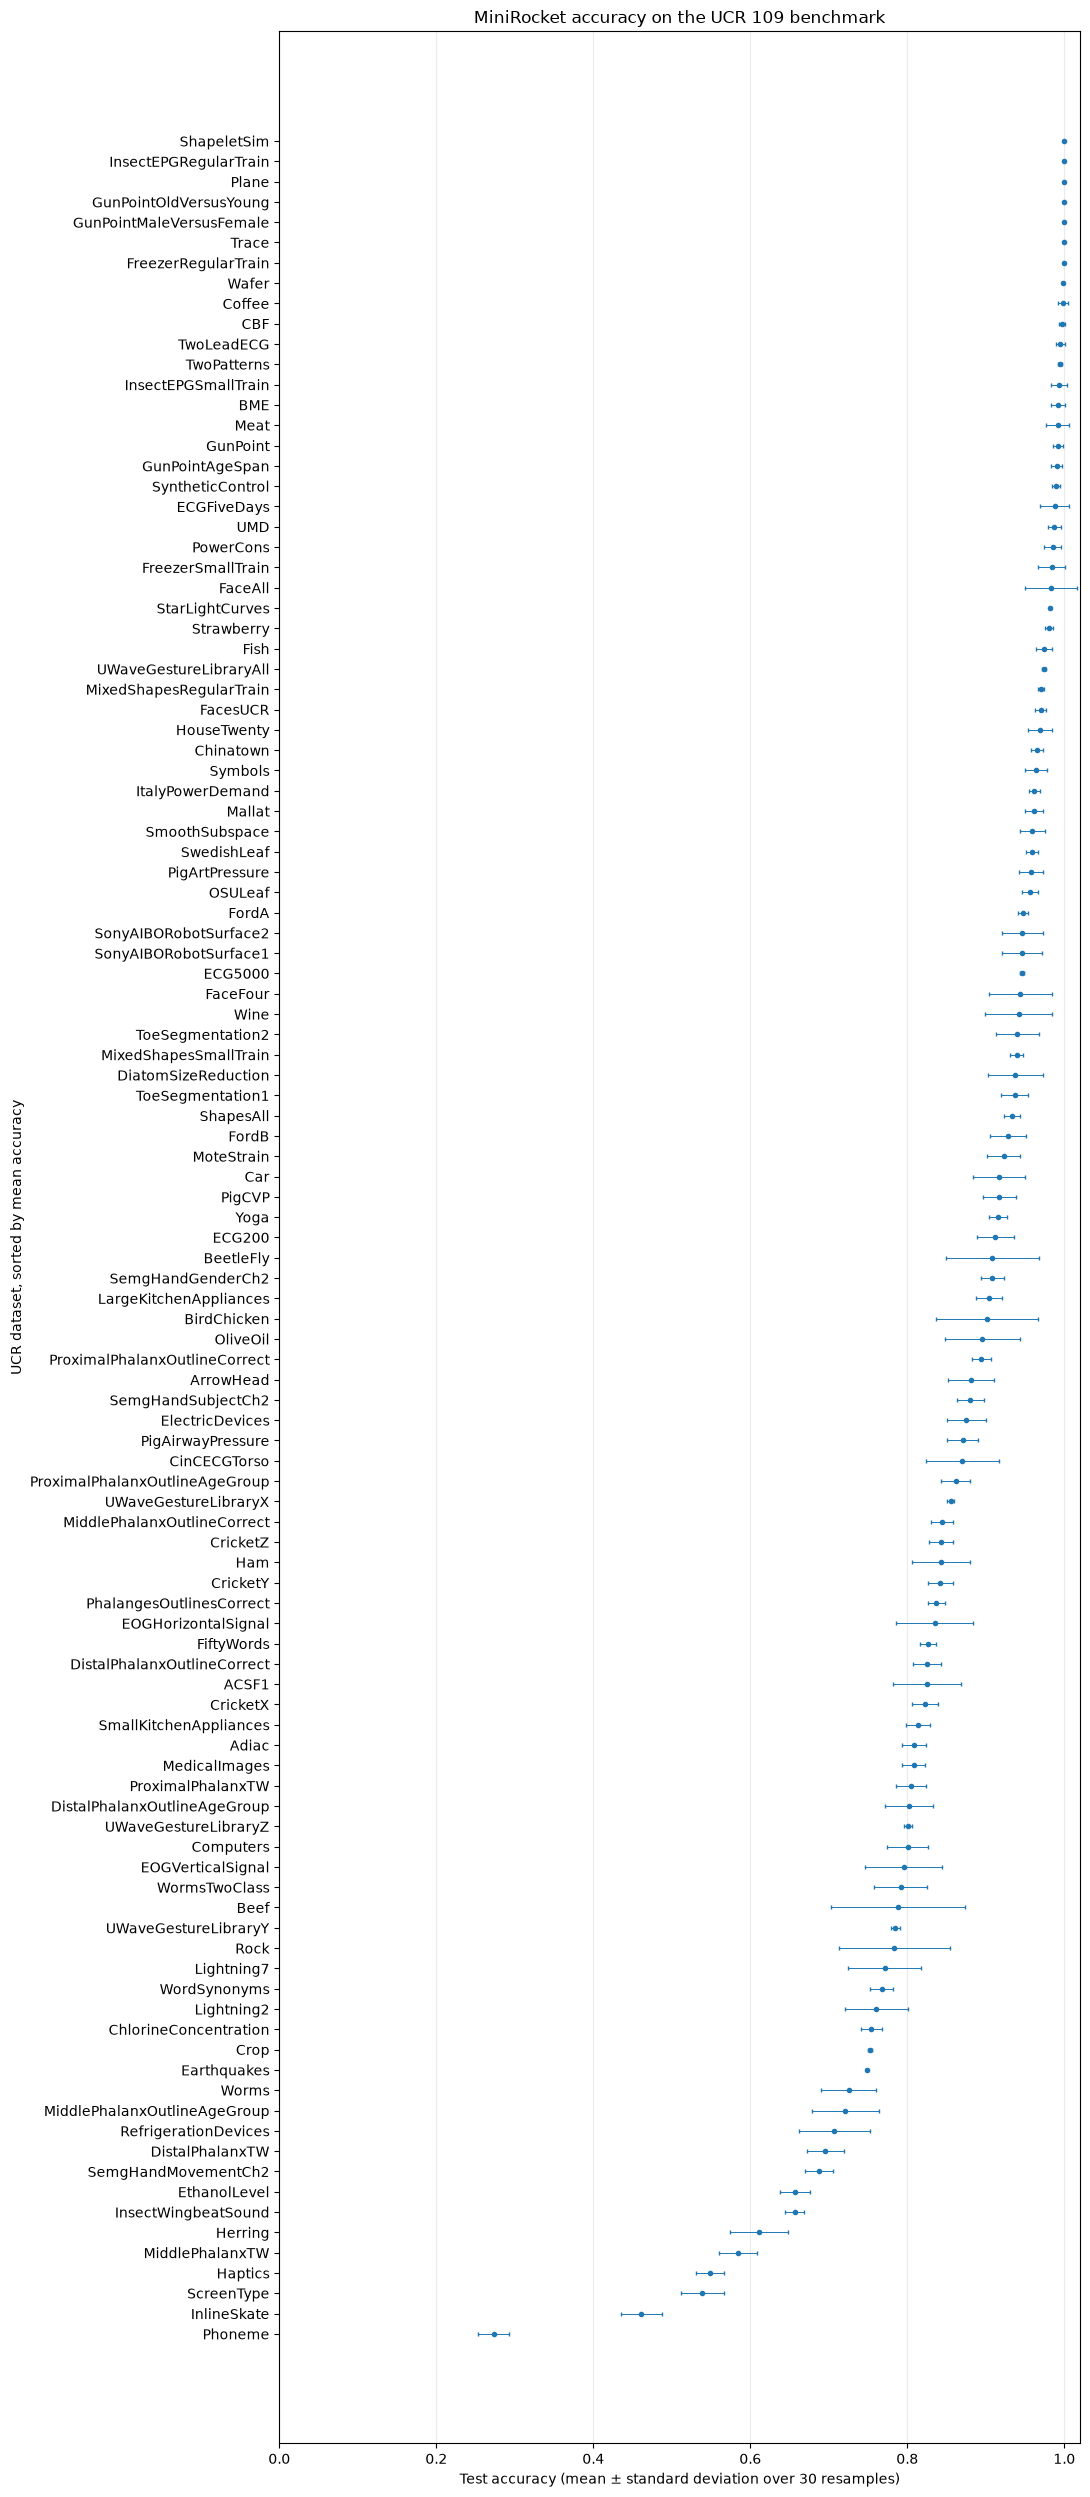

Plot saved to: /Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series/minirocket_ucr109_results/minirocket_mean_accuracy_by_dataset.png


,dataset,mean_accuracy (lowest 10),std_accuracy,mean_transform_seconds,mean_total_seconds
67,Phoneme,0.273259,0.019823,3.176473,3.252359
47,InlineSkate,0.461212,0.026349,1.936201,1.956730
78,ScreenType,0.539022,0.027075,0.813872,0.884847
44,Haptics,0.548593,0.017546,0.797327,0.818354
60,MiddlePhalanxTW,0.584199,0.024266,0.073351,0.137595
45,Herring,0.611458,0.036869,0.130134,0.138243
50,InsectWingbeatSound,0.656313,0.012440,0.819307,0.878243
29,EthanolLevel,0.657133,0.019073,2.709642,2.800139
80,SemgHandMovementCh2,0.687037,0.017960,2.062248,2.148238
21,DistalPhalanxTW,0.695683,0.023073,0.116184,0.209368


,dataset,mean_accuracy,std_accuracy,mean_transform_seconds,mean_total_seconds
95,Trace,1.000000,0.000000,0.105201,0.118607
41,GunPointMaleVersusFemale,1.000000,0.000000,0.116708,0.134591
42,GunPointOldVersusYoung,1.000000,0.000000,0.116515,0.134135
71,Plane,1.000000,0.000000,0.059640,0.073613
48,InsectEPGRegularTrain,1.000000,0.000000,0.317475,0.329632
82,ShapeletSim,1.000000,0.000000,0.184106,0.191415
37,FreezerRegularTrain,0.999029,0.001089,1.331266,1.380168
103,Wafer,0.998940,0.000986,1.577147,1.947473
12,Coffee,0.998810,0.006521,0.077260,0.085093
7,CBF,0.997148,0.004335,0.306598,0.334421


In [5]:
# One point per dataset: mean test accuracy across its 30 resamples, with standard deviation
per_resample = pd.read_csv(PER_RESAMPLE_CSV)
summary = (
    per_resample.groupby("dataset", as_index=False)
    .agg(
        mean_accuracy=("accuracy", "mean"),
        std_accuracy=("accuracy", "std"),
        mean_transform_seconds=("transform_seconds", "mean"),
        mean_total_seconds=("total_seconds", "mean"),
    )
    .sort_values("mean_accuracy")
)
summary.to_csv(SUMMARY_CSV, index=False)

fig_height = max(12, 0.23 * len(summary))
fig, ax = plt.subplots(figsize=(11, fig_height))
ax.errorbar(
    summary["mean_accuracy"],
    summary["dataset"],
    xerr=summary["std_accuracy"].fillna(0),
    fmt="o",
    markersize=3,
    elinewidth=0.7,
    capsize=1.5,
)
ax.set_xlabel("Test accuracy (mean ± standard deviation over 30 resamples)")
ax.set_ylabel("UCR dataset, sorted by mean accuracy")
ax.set_title("MiniRocket accuracy on the UCR 109 benchmark")
ax.set_xlim(0, 1.02)
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
fig.savefig(PLOT_PATH, dpi=180, bbox_inches="tight")
plt.show()

print("Plot saved to:", PLOT_PATH)
display(summary.head(10).rename(columns={"mean_accuracy": "mean_accuracy (lowest 10)"}))
display(summary.tail(10).sort_values("mean_accuracy", ascending=False))

## 5. Comparison with the published results

This section compares our results with the per-resample accuracies the authors published in `accuracy_ucr109_resamples.csv`. It was added after the benchmark had been run. The cell reads only the saved result files (`minirocket_per_resample.csv` and `minirocket_per_dataset_summary.csv`), so it uses exactly the accuracies recorded in Section 3 and can be run on its own, without repeating the benchmark or generating new splits. We compare in two ways.

First, we compare the per-dataset means over 30 resamples, as reported in the paper. Since our resamples 1–29 differ from the authors', some per-dataset difference is expected, particularly on datasets with small test sets, where a single misclassified example moves accuracy by several percentage points. We report the mean accuracy of both, the win/draw/loss count (treating differences under 0.05 percentage points as draws), the number of datasets within one percentage point, and a Wilcoxon signed-rank test on the paired per-dataset means.

Second, we compare resample 0 only. This is the original UCR split, identical in our runs and the authors', so any difference there comes only from MiniRocket's unseeded bias sampling and from differences in software environment.

The pairwise plot follows the layout of Figure 4 in the paper: points above the diagonal are datasets where our reproduction is more accurate.

Mean accuracy, our reproduction: 0.8724
Mean accuracy, published:        0.8724
Win / draw / loss (ours vs published): 40 / 22 / 47
Datasets within 1 percentage point: 101 of 109
Mean absolute difference: 0.34 percentage points
Wilcoxon signed-rank test: statistic=2554.0, p=0.465

Original split only (resample 0, identical split in both runs):
  Mean accuracy, ours vs published: 0.8570 vs 0.8567
  Identical accuracy on 14 of 109 datasets
  Mean absolute difference: 0.51 percentage points

Sum of mean transform times over 109 datasets: 110.5 s (paper: about 150 s)
Sum of mean total times over 109 datasets:     404.5 s


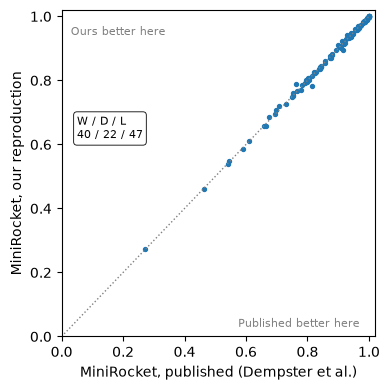

,dataset,mean_accuracy,mean_transform_seconds,mean_total_seconds,published_mean,published_default_split,our_default_split,difference,default_split_difference
19,Rock,0.783333,0.460398,0.466834,0.815333,0.800000,0.800000,-0.032000,0.000000e+00
21,Beef,0.787778,0.128366,0.138077,0.761111,0.866667,0.866667,0.026667,-3.333333e-07
49,OliveOil,0.895556,0.089371,0.095543,0.914444,0.933333,0.933333,-0.018889,3.333333e-07
65,Wine,0.941975,0.059842,0.066864,0.927778,0.870370,0.851852,0.014198,-1.851815e-02
11,MiddlePhalanxOutlineAgeGroup,0.720996,0.073483,0.135549,0.708009,0.610390,0.616883,0.012987,6.493117e-03
54,ECG200,0.912000,0.064174,0.081263,0.899333,0.910000,0.920000,0.012667,1.000000e-02
8,SemgHandMovementCh2,0.687037,2.062248,2.148238,0.675037,0.691111,0.657778,0.012000,-3.333322e-02
10,RefrigerationDevices,0.707200,0.820572,0.892135,0.696978,0.477333,0.493333,0.010222,1.600033e-02
58,MoteStrain,0.922710,0.167955,0.191410,0.912913,0.930511,0.929712,0.009798,-7.985399e-04
16,Lightning2,0.760656,0.163014,0.171363,0.751912,0.737705,0.737705,0.008743,-8.196721e-08


In [2]:
# This cell is self-contained: it reads the saved result files from disk,
# so it can be run in a fresh session without repeating the benchmark.
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import wilcoxon

PROJECT = Path("/Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series")
REFERENCE_RESULTS = PROJECT / "minirocket" / "results" / "accuracy_ucr109_resamples.csv"
OUTPUT_DIR = PROJECT / "minirocket_ucr109_results"
PER_RESAMPLE_CSV = OUTPUT_DIR / "minirocket_per_resample.csv"
SUMMARY_CSV = OUTPUT_DIR / "minirocket_per_dataset_summary.csv"
per_resample = pd.read_csv(PER_RESAMPLE_CSV)

# Published per-resample accuracies from the authors' repository
published = pd.read_csv(REFERENCE_RESULTS)
resample_columns = [column for column in published.columns if column != "dataset"]
published["published_mean"] = published[resample_columns].mean(axis=1)
published["published_default_split"] = published["0"]

# Our per-dataset means, and our accuracy on the original split (resample 0)
ours = pd.read_csv(SUMMARY_CSV)[["dataset", "mean_accuracy", "mean_transform_seconds", "mean_total_seconds"]]
ours_default = (
    per_resample[per_resample["resample"] == 0][["dataset", "accuracy"]]
    .rename(columns={"accuracy": "our_default_split"})
)
comparison = (
    ours.merge(published[["dataset", "published_mean", "published_default_split"]], on="dataset")
    .merge(ours_default, on="dataset")
)
comparison["difference"] = comparison["mean_accuracy"] - comparison["published_mean"]
comparison["default_split_difference"] = (
    comparison["our_default_split"] - comparison["published_default_split"]
)

draw_tolerance = 0.0005  # differences under 0.05 percentage points count as draws
wins = int((comparison["difference"] > draw_tolerance).sum())
losses = int((comparison["difference"] < -draw_tolerance).sum())
draws = len(comparison) - wins - losses
statistic, p_value = wilcoxon(comparison["mean_accuracy"], comparison["published_mean"])

print(f"Mean accuracy, our reproduction: {comparison['mean_accuracy'].mean():.4f}")
print(f"Mean accuracy, published:        {comparison['published_mean'].mean():.4f}")
print(f"Win / draw / loss (ours vs published): {wins} / {draws} / {losses}")
print(f"Datasets within 1 percentage point: {(comparison['difference'].abs() <= 0.01).sum()} of {len(comparison)}")
print(f"Mean absolute difference: {comparison['difference'].abs().mean() * 100:.2f} percentage points")
print(f"Wilcoxon signed-rank test: statistic={statistic:.1f}, p={p_value:.3f}")
print()
print("Original split only (resample 0, identical split in both runs):")
print(f"  Mean accuracy, ours vs published: "
      f"{comparison['our_default_split'].mean():.4f} vs {comparison['published_default_split'].mean():.4f}")
print(f"  Identical accuracy on {(comparison['default_split_difference'].abs() < 1e-9).sum()} of {len(comparison)} datasets")
print(f"  Mean absolute difference: {comparison['default_split_difference'].abs().mean() * 100:.2f} percentage points")
print()
print(f"Sum of mean transform times over 109 datasets: {comparison['mean_transform_seconds'].sum():.1f} s "
      f"(paper: about 150 s)")
print(f"Sum of mean total times over 109 datasets:     {comparison['mean_total_seconds'].sum():.1f} s")

# Pairwise plot in the style of Figure 4 of the paper
fig, ax = plt.subplots(figsize=(4, 4))
ax.plot([0, 1], [0, 1], linestyle=":", color="grey", linewidth=1)
ax.scatter(comparison["published_mean"], comparison["mean_accuracy"], s=8)
ax.set_xlim(0, 1.02)
ax.set_ylim(0, 1.02)
ax.set_xlabel("MiniRocket, published (Dempster et al.)")
ax.set_ylabel("MiniRocket, our reproduction")
ax.text(0.03, 0.97, "Ours better here", color="grey", va="top", fontsize=8)
ax.text(0.97, 0.03, "Published better here", color="grey", ha="right", fontsize=8)
ax.text(0.05, 0.62, f"W / D / L\n{wins} / {draws} / {losses}", fontsize=8,
        bbox=dict(boxstyle="round", facecolor="white", edgecolor="black", linewidth=0.6))
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "minirocket_vs_published_pairwise.png", dpi=300, bbox_inches="tight")
plt.show()

comparison.to_csv(OUTPUT_DIR / "minirocket_vs_published.csv", index=False)
display(comparison.reindex(comparison["difference"].abs().sort_values(ascending=False).index).head(10))

## 6. Recording the experimental setup

To make our own results reproducible, we record the full experimental setup alongside them in `experiment_metadata.json`: the MiniRocket repository commit, the dataset list, the resampling protocol and seed, the classifier and normalisation settings, the thread count, how timings were measured, the machine's platform and CPU, and the versions of Python, NumPy, pandas, scikit-learn, aeon and Numba.

In [7]:
import json
import platform
import subprocess
import sys
from datetime import datetime, timezone
from importlib.metadata import PackageNotFoundError, version
from pathlib import Path

import pandas as pd


PROJECT = Path(
    "/Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series"
)
REPO = PROJECT / "minirocket"
OUTPUT_DIR = PROJECT / "minirocket_ucr109_results"
REFERENCE_RESULTS = REPO / "results" / "accuracy_ucr109_resamples.csv"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def package_version(package_name):
    try:
        return version(package_name)
    except PackageNotFoundError:
        return "not installed"


# The MiniRocket repository revision we ran, if Git is available
try:
    repository_commit = subprocess.run(
        ["git", "-C", str(REPO), "rev-parse", "HEAD"],
        capture_output=True,
        text=True,
        check=True,
    ).stdout.strip()
except (FileNotFoundError, subprocess.CalledProcessError):
    repository_commit = "unavailable"


# The benchmark dataset names from the authors' reference file
if REFERENCE_RESULTS.exists():
    dataset_names = pd.read_csv(REFERENCE_RESULTS)["dataset"].astype(str).tolist()
else:
    dataset_names = "Reference results file not found"


metadata = {
    "recorded_utc": datetime.now(timezone.utc).isoformat(),
    "method": "MiniRocket",
    "repository": str(REPO),
    "repository_commit": repository_commit,
    "dataset_archive": str(PROJECT / "UCR Archive 2018"),
    "benchmark_datasets": dataset_names,
    "number_of_datasets": (
        len(dataset_names) if isinstance(dataset_names, list) else "unknown"
    ),
    "number_of_resamples": 30,
    "resampling_protocol": (
        "Resample 0 uses the supplied train/test split. Resamples 1-29 "
        "combine the supplied train and test cases, then make seeded "
        "stratified splits preserving the original training count per class."
    ),
    "split_seed": 2026,
    "minirocket_features": 10000,
    "classifier": "RidgeClassifierCV",
    "ridge_alphas": "10 values from 10^-3 to 10^3",
    "feature_normalization": (
        "Center transformed training features and divide each feature "
        "by its training-set L2 norm; apply the same values to test features."
    ),
    "cpu_threads": 1,
    "timing_notes": (
        "Data loading and initial Numba warm-up are excluded. Transform time "
        "includes MiniRocket fit and train/test transformation. Total time "
        "includes feature normalization, classifier fitting, and prediction."
    ),
    "randomness_note": (
        "The default MiniRocket fit uses Numba's internal random generator "
        "for threshold fitting; this notebook does not seed that generator."
    ),
    "machine": {
        "platform": platform.platform(),
        "processor": platform.processor() or "not reported",
        "architecture": platform.machine(),
        "logical_cpu_count": __import__("os").cpu_count(),
    },
    "software_versions": {
        "python": sys.version.split()[0],
        "numpy": package_version("numpy"),
        "pandas": package_version("pandas"),
        "scikit_learn": package_version("scikit-learn"),
        "aeon": package_version("aeon"),
        "numba": package_version("numba"),
    },
    "saved_split_directory": str(OUTPUT_DIR / "splits"),
}

metadata_path = OUTPUT_DIR / "experiment_metadata.json"
with metadata_path.open("w") as f:
    json.dump(metadata, f, indent=2)

print("Metadata saved to:", metadata_path)

Metadata saved to: /Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series/minirocket_ucr109_results/experiment_metadata.json


## 7. How the saved splits are reused in our improvement experiments

Each dataset has a file in the `splits` folder containing the training and test indices for all 30 resamples (`train_00`/`test_00` through `train_29`/`test_29`). The indices refer to the combined array in which the original training rows come first, followed by the original test rows. Our anti-aliasing and ordered co-activation pooling experiments load these files and use the same normalisation and classifier as above, so any difference in accuracy from this baseline is due to the method rather than to the choice of splits.

The saved indices fix the data partitions, but they do not make MiniRocket's output fully deterministic. When fitting biases, the default MiniRocket selects training examples using Numba's internal random number generator, which we did not seed. Repeating a run on the same split can therefore give a slightly different accuracy, and this is part of the run-to-run variation in any comparison against this baseline.